**quantum_runs** - executed copy of `Noise_Simulation.ipynb` (run `noise_sim_1000q`).

Parameter overrides: `N_QUBITS=1000 BACKEND="cpu" LIVE_MEMORY_DISPLAY=False EXPORT_DIR="exports"`

# Quantum Noise Simulation
### How gate errors degrade a quantum circuit, simulated with NVIDIA CUDA-Q
*Notebook 7 of 8 - CUDA-Q Quantum Algorithm Benchmarking Suite*

This notebook runs the same circuit with and without a noise model, compares the ideal and noisy measurement distributions, computes fidelities, and sweeps the error probability to show how noise destroys the quantum state. It uses CUDA-Q's noise-capable simulators (stabilizer, density matrix and GPU trajectory simulation) and measures time and memory.

**How to use this notebook:** run all cells from top to bottom (*Kernel -> Restart & Run All*).
Change parameters **only in Section 3**; every later cell reads them from there. The default
configuration runs immediately on a laptop CPU and much faster on an NVIDIA GPU.

| Section | Content |
|---|---|
| 1 | Problem statement and mathematical explanation |
| 2 | Import libraries (with installation instructions) |
| 3 | Input parameters - **the only cell you need to edit** |
| 4 | Example inputs |
| 5 | Benchmark utilities and backend initialization |
| 6 | Expected output (computed *before* running the quantum circuit) |
| 7 | Quantum circuit generation and visualization |
| 8 | Execution with live memory monitoring |
| 9 | Results and visualization |
| 10 | Final benchmark report |

---
## Section 1 - Problem statement and mathematical explanation

### What problem does the simulation solve?
Real quantum computers are **noisy**: every gate has a small probability of error and qubits lose their state
(decoherence). Noise simulation predicts what a circuit produces on such hardware, so we can decide whether an
algorithm will still work and how good the hardware must be.

### Why is this important?
* It quantifies the error rates needed for an algorithm to succeed (hardware requirements, error budgets).
* It is used to develop and test error mitigation and error correction before running on hardware.
* It explains why today's devices are limited to shallow circuits: errors accumulate with every gate.

### What is the classical approach?
A noisy state is a **density matrix** $\rho$ ($2^N \times 2^N$, i.e. $4^N$ numbers). Each gate $U$ acts as
$\rho \to U\rho U^\dagger$, followed by a **noise channel** written with Kraus operators:

$$\mathcal{E}(\rho) = \sum_k K_k\,\rho\,K_k^\dagger,\qquad \sum_k K_k^\dagger K_k = I .$$

Exact density-matrix simulation costs $4^N$ memory. Two cheaper exact-in-distribution alternatives exist:
**Monte-Carlo trajectories** (state vectors, $2^N$, errors inserted at random - CUDA-Q's GPU simulators) and the
**stabilizer formalism** (polynomial cost, but only for Clifford circuits with Pauli noise - CUDA-Q's `stim` target).

### Noise channels used here (probability $p$, applied after every gate)
| Channel | Kraus operators | Physical meaning |
|---|---|---|
| depolarizing | $\sqrt{1-p}\,I,\ \sqrt{p/3}\,X,\ \sqrt{p/3}\,Y,\ \sqrt{p/3}\,Z$ (2-qubit gates: $\sqrt{1-p}\,II$ + 15 Paulis with $p/15$) | random Pauli error |
| bit flip | $\sqrt{1-p}\,I,\ \sqrt{p}\,X$ | $|0\rangle \leftrightarrow |1\rangle$ flips |
| phase flip | $\sqrt{1-p}\,I,\ \sqrt{p}\,Z$ | loss of phase coherence (dephasing) |
| amplitude damping | $\begin{pmatrix}1&0\\0&\sqrt{1-p}\end{pmatrix},\ \begin{pmatrix}0&\sqrt{p}\\0&0\end{pmatrix}$ | energy relaxation $|1\rangle\to|0\rangle$ ($T_1$) |

For two-qubit gates the bit-flip, phase-flip and amplitude-damping channels act independently on both qubits.

### The circuits
* **GHZ state** (default): $H$ on qubit 0 and a CNOT chain give
  $|\mathrm{GHZ}\rangle = \tfrac{1}{\sqrt2}(|0\cdots0\rangle + |1\cdots1\rangle)$, a maximally entangled state that is
  extremely sensitive to noise. It is a Clifford circuit, so the stabilizer simulator can handle many qubits.
* **Mirror circuit**: random rotation layers $U$ followed by $U^\dagger$; ideally it returns exactly
  $|0\cdots0\rangle$. Its rotations are not Clifford gates, so it needs density-matrix or trajectory simulation.

### Measurement and figures of merit
* **Z basis**: ideal GHZ gives $0\cdots0$ and $1\cdots1$ with 50 % each. The **GHZ population**
  $P_{\text{pop}} = P(0\cdots0) + P(1\cdots1)$ drops when bit flips occur.
* **X basis** (Hadamard on every qubit before measuring): ideal GHZ gives only even-parity bitstrings, so
  $\langle X^{\otimes N}\rangle = 1$. Phase errors are **invisible in the Z basis** but reduce this parity.
* **Hellinger (classical) fidelity** between ideal distribution $p$ and noisy distribution $q$:
  $F_H = \big(\sum_x \sqrt{p_x q_x}\big)^2$ (1 = identical).
* **State fidelity** (density-matrix method only): $F = \langle\psi_{\text{ideal}}|\rho|\psi_{\text{ideal}}\rangle$,
  and **purity** $\mathrm{Tr}\,\rho^2$ (1 for a pure state).

### Expected solution
Without noise the ideal results above are reproduced exactly. With error probability $p$ per gate and $G$ noisy gate
locations, the probability that *no* error occurs is $(1-p)^{G}$ - a lower bound on the fidelity for Pauli noise -
so fidelity decays roughly exponentially with $p\cdot G$: **more qubits and deeper circuits are more fragile**.

---
## Section 2 - Import libraries

All quantum code uses **NVIDIA CUDA-Q** (`cudaq`). The other libraries are standard scientific Python.

**Installation** (Linux x86_64/aarch64 with or without an NVIDIA GPU, or macOS on Apple silicon for CPU-only simulation):

```bash
python3 -m venv cudaq-env && source cudaq-env/bin/activate     # Python >= 3.11
pip install --upgrade pip
pip install cudaq numpy scipy matplotlib psutil nvidia-ml-py jupyter
```

* `pip install cudaq` detects your CUDA driver and installs the matching CUDA-Q build (CUDA 12.x or 13.x).
  A GPU is **not** required: CPU simulators are always available.
* `nvidia-ml-py` provides NVML bindings used for GPU memory monitoring (optional on CPU-only machines).
* Multi-GPU / multi-node runs additionally need MPI; see the README of this repository.

The next cell imports everything, prints the versions found and warns about incompatible versions.

In [1]:
# ---------------------------------------------------------------------------------
# Section 2 - Import libraries and check versions
# ---------------------------------------------------------------------------------
import os, sys, re, json, math, time, socket, platform      # standard library: files, timing, system info
import threading, subprocess, tempfile, datetime            # standard library: live memory monitor + report
import warnings                                             # used to hide two harmless CUDA-Q notices

# CUDA-Q 0.16 prints two informational warnings when imported: a "preview" notice for the
# bundled cudaq-logical package and a notice that sample/observe will change in a FUTURE
# release. Neither affects this notebook, so exactly these two messages are hidden.
warnings.filterwarnings("ignore", message=".*cudaq-logical is in preview.*")
warnings.filterwarnings("ignore", message=".*algorithmic primitives will change.*")

_missing = []                                               # collect missing packages for one clear message
try:
    import numpy as np                                      # arrays, linear algebra, random numbers
except ImportError:
    _missing.append("numpy")
try:
    import matplotlib                                       # plotting library
    import matplotlib.pyplot as plt                         # pyplot interface for figures
except ImportError:
    _missing.append("matplotlib")
try:
    import scipy                                            # scientific computing (optimizers, linear algebra)
    pass
except ImportError:
    _missing.append("scipy")
try:
    import psutil                                           # host RAM monitoring
except ImportError:
    _missing.append("psutil")
try:
    import cudaq                                            # NVIDIA CUDA-Q: kernels, simulators, QPU targets
except ImportError:
    _missing.append("cudaq")
if _missing:
    raise ImportError(f"Missing packages: {_missing}. Install them with:\n"
                      f"    pip install {' '.join(_missing)} nvidia-ml-py\n"
                      "CUDA-Q needs Linux (x86_64/aarch64) or macOS on Apple silicon (CPU only); see README.md.")

try:
    import pynvml                                           # NVIDIA Management Library bindings (GPU memory)
    HAVE_NVML = True
except ImportError:                                         # optional: only needed for GPU monitoring
    pynvml, HAVE_NVML = None, False

try:                                                        # live display inside Jupyter
    from IPython import get_ipython
    from IPython.display import display, Pretty
    _IN_JUPYTER = get_ipython() is not None and "IPKernelApp" in get_ipython().config
except Exception:                                           # running as a plain Python script
    display, Pretty, _IN_JUPYTER = None, None, False

# ---- Version report and compatibility check ----------------------------------------
_match = re.search(r"(\d+)\.(\d+)\.(\d+)", cudaq.__version__)
CUDAQ_VERSION = ".".join(_match.groups()) if _match else cudaq.__version__
_cudaq_tuple = tuple(int(x) for x in _match.groups()) if _match else (0, 0, 0)
print(f"Python      : {platform.python_version()} ({platform.system()} {platform.machine()})")
print(f"CUDA-Q      : {CUDAQ_VERSION}")
print(f"NumPy       : {np.__version__}")
print(f"SciPy       : {scipy.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"psutil      : {psutil.__version__}")
print(f"nvidia-ml-py: {'installed' if HAVE_NVML else 'NOT installed (GPU memory monitoring disabled: pip install nvidia-ml-py)'}")
print(f"GPUs visible to CUDA-Q: {cudaq.num_available_gpus()}")
if sys.version_info < (3, 11):
    print("WARNING: CUDA-Q 0.16 wheels require Python >= 3.11.")
if _cudaq_tuple < (0, 12, 0):
    print("WARNING: this notebook was written and tested with CUDA-Q 0.16.0; versions older than 0.12 "
          "use a different operator API and are not supported. Upgrade with: pip install -U cudaq")
elif _cudaq_tuple != (0, 16, 0):
    print("Note: tested with CUDA-Q 0.16.0. Other versions should work; if an API error appears, "
          "compare with the README's 'Known limitations'.")

# ---------------------------------------------------------------------------------
# Plot style used by every figure: colour-blind-safe palette, hairline grid, one y-axis per chart
# ---------------------------------------------------------------------------------
# Categorical colours in a FIXED order (validated for colour-vision deficiency).
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA = SERIES_COLORS[0], SERIES_COLORS[1], SERIES_COLORS[2]
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"   # text colours
GRID_COLOR, AXIS_COLOR, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"  # chart chrome
GOOD, CRITICAL = "#0ca30c", "#d03b3b"                                # reserved status colours
SEQUENTIAL_BLUE = matplotlib.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])          # magnitude
DIVERGING_BLUE_RED = matplotlib.colors.LinearSegmentedColormap.from_list(
    "div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#a32b2b"])      # signed values


def apply_plot_style():
    """Consistent, quiet chart style for every figure in this notebook."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": AXIS_COLOR, "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK,
        "text.color": INK, "xtick.color": AXIS_COLOR, "ytick.color": AXIS_COLOR,
        "xtick.labelcolor": INK_SECONDARY, "ytick.labelcolor": INK_SECONDARY,
        "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8, "grid.linestyle": "-",
        "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
        "axes.prop_cycle": matplotlib.cycler(color=SERIES_COLORS),
        "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.markersize": 6,
        "legend.frameon": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 100,
    })


apply_plot_style()

Python      : 3.13.18 (Linux x86_64)
CUDA-Q      : 0.16.0
NumPy       : 2.5.4
SciPy       : 1.18.1
Matplotlib  : 3.11.2
psutil      : 7.2.2
nvidia-ml-py: NOT installed (GPU memory monitoring disabled: pip install nvidia-ml-py)
GPUs visible to CUDA-Q: 0


---
## Section 3 - Input parameters

This is the **only cell you need to edit**. Every later cell reads these variables.

In [2]:
# =====================================================================================
# Section 3 - INPUT PARAMETERS  (edit only this cell, then re-run the notebook)
# =====================================================================================

# ---- Problem definition: circuit and noise ----------------------------------------------
N_QUBITS = 1000                    # qubits in the circuit (density matrix: keep <= 10; stabilizer: hundreds possible)
CIRCUIT = "ghz"                  # "ghz" (Clifford, default) | "mirror" (random rotations + inverse, non-Clifford)
MIRROR_LAYERS = 2                # "mirror": random layers before the inverse (circuit depth ~ 2 x layers)
NOISE_MODEL = "depolarizing"     # "depolarizing" | "bit_flip" | "phase_flip" | "amplitude_damping"
NOISE_PROBABILITY = 0.01         # error probability p after every gate (0 = noiseless)
NOISE_SWEEP = [0.0, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]   # p values for the "fidelity vs noise" plot
MEASURE_X_BASIS = True           # GHZ only: also measure in the X basis (reveals phase errors)

# ---- Backend and simulation method ---------------------------------------------------
BACKEND = "cpu"                 # "auto" | "cpu" | "gpu" | "multi-gpu" | "hardware"
SIMULATION_METHOD = "auto"   # "auto" | "stabilizer" (CPU) | "density_matrix" (CPU) | "trajectory" (GPU)
GPU_PRECISION = "fp64"            # "fp64" (16 B/amplitude) | "fp32" (8 B/amplitude, half the memory)
HARDWARE_PROVIDER = "quantinuum"  # only for BACKEND="hardware": "quantinuum", "ionq", "oqc", "anyon", "infleqtion", ...
HARDWARE_EMULATE = True           # True: local emulation (no account, no cost); False: real QPU (credentials needed)
HARDWARE_MACHINE = None           # provider device name, e.g. "H2-1E"; None = provider default

# ---- Shots and reproducibility --------------------------------------------------------
SHOTS = 10000                       # measurement repetitions; statistical error ~ 1/sqrt(SHOTS)
SEED = 42                         # fixes NumPy and CUDA-Q random numbers -> reproducible results

# ---- Memory monitoring ----------------------------------------------------------------
LIVE_MEMORY_DISPLAY = False        # live RAM / GPU memory line while the execution cell runs
MEMORY_SAMPLE_INTERVAL_S = 0.25   # sampling period in seconds (smaller = finer timeline)
MEMORY_SAFETY_FRACTION = 0.8      # refuse runs whose state needs more than 80% of free memory

# ---- Circuit drawing, export and report ---------------------------------------------------
DRAW_QUBITS = 10                  # qubits shown in the circuit drawing (maximum 10)
EXPORT_CIRCUIT = True             # save drawing + full circuit to EXPORT_DIR
EXPORT_FORMATS = ["txt", "png", "qir"]   # "txt", "png" (drawing), "qir", "qasm" (full circuit)
EXPORT_DIR = "exports"     # output folder (created automatically)
SAVE_REPORT = True                # save the final benchmark report (JSON) and figure (PNG)

#### What every parameter means and what happens when you change it

| Parameter | Meaning | Effect of changing it |
|---|---|---|
| `N_QUBITS` | Width of the circuit. | More qubits = more gates = more errors (fidelity drops). Memory: stabilizer ~N^2 bits, trajectory 16 x 2^N bytes, density matrix 16 x 4^N bytes (N = 12 needs 268 MB, N = 14 needs 4.3 GB). |
| `CIRCUIT` / `MIRROR_LAYERS` | Which circuit is simulated. | GHZ works with every method; the mirror circuit is non-Clifford (no stabilizer method). More mirror layers = deeper circuit = lower fidelity. |
| `NOISE_MODEL` | Kind of error (table in Section 1). | Bit flips lower the Z-basis population, phase flips only the X-basis parity, depolarizing noise both, amplitude damping biases outcomes towards 0. The stabilizer method supports only Pauli channels (not amplitude damping). |
| `NOISE_PROBABILITY` | Error probability $p$ per gate. | Fidelity decays roughly like $(1-p)^G$. Real devices: $p \approx 10^{-4}-10^{-2}$. |
| `NOISE_SWEEP` | Probabilities for the sweep plot. | More values = smoother curve, proportionally more run time. |
| `MEASURE_X_BASIS` | Extra X-basis run for GHZ. | Needed to see phase errors; doubles the number of runs. |
| `SIMULATION_METHOD` | `"auto"` picks: GPU -> `"trajectory"`; CPU -> `"stabilizer"` for GHZ with Pauli noise, otherwise `"density_matrix"`. | The noiseless state-vector simulators ignore noise, so they are not offered here. |
| `BACKEND` | Where the circuit runs: `"auto"` (NVIDIA GPU if CUDA-Q sees one, otherwise CPU), `"cpu"`, `"gpu"`, `"multi-gpu"`, `"hardware"`. | GPU state-vector simulation is typically 10-1000x faster than CPU for N >= 20 and is limited by GPU memory. `"multi-gpu"` pools the memory of several GPUs (launch with MPI, see README). `"hardware"` sends the circuit to a quantum computer provider (sampling only). |
| `SIMULATION_METHOD` | How the quantum state is stored (the allowed values for this notebook are listed in the input cell). `"statevector"`: all 2^N amplitudes, exact. `"mps"`: matrix product state, compressed (GPU). `"tensornet"`: exact tensor-network contraction (GPU). `"density_matrix"`: 4^N entries, supports noise (CPU). | Changes memory and run time: state vector needs 16 x 2^N bytes (fp64), density matrix 16 x 4^N bytes, MPS grows with entanglement instead of with N. An unsupported combination stops with an explanation. |
| `GPU_PRECISION` | `"fp64"` (16 bytes per amplitude) or `"fp32"` (8 bytes). GPU targets only; CPU targets always use fp64. | fp32 halves memory (one more qubit fits) and is faster, with ~1e-7 relative precision instead of ~1e-16. |
| `HARDWARE_PROVIDER` / `HARDWARE_EMULATE` / `HARDWARE_MACHINE` | Used only when `BACKEND="hardware"`: provider target (`"quantinuum"`, `"ionq"`, `"oqc"`, `"anyon"`, `"infleqtion"`, ...), local emulation switch, device name. | `HARDWARE_EMULATE=True` runs the provider's compilation flow locally with no account and no cost. `False` submits real jobs: needs credentials, may cost money, waits in a queue. |
| `SHOTS` | Number of times the circuit is executed and measured. | Statistical error of every measured probability shrinks like 1/sqrt(SHOTS). On simulators extra shots are cheap; on hardware cost grows linearly. |
| `SEED` | Random seed for NumPy and CUDA-Q's shot sampler. | Same seed gives identical results on re-run; change it to see statistical fluctuations. |
| `LIVE_MEMORY_DISPLAY` / `MEMORY_SAMPLE_INTERVAL_S` | Live RAM/GPU memory line during execution; sampling period in seconds. | Smaller intervals give a finer memory timeline; peaks shorter than the interval can be missed. |
| `MEMORY_SAFETY_FRACTION` | The run is refused if the quantum state would need more than this fraction of the free memory. | Raise it (e.g. 0.95) if you know the run fits; lower it to protect other work on the machine. |
| `DRAW_QUBITS` | Number of qubits used for the circuit **drawing** (at most 10). | Only changes the picture; execution always uses the full number of qubits. |
| `EXPORT_CIRCUIT` / `EXPORT_FORMATS` / `EXPORT_DIR` / `SAVE_REPORT` | Save the drawing (`"txt"`, `"png"`), the full circuit (`"qir"`, `"qasm"`), the report (JSON) and final figure (PNG) to `EXPORT_DIR`. | Set `EXPORT_CIRCUIT=False` / `SAVE_REPORT=False` to write nothing to disk. |

---
## Section 4 - Example inputs

**Default example (runs as is):** a 15-qubit GHZ circuit with depolarizing noise $p = 0.01$ after every gate,
10 000 shots, and a sweep over $p \in [0, 0.1]$. On a CPU it uses the stabilizer simulator (`stim`); on a GPU
the trajectory simulator.

| Goal | Setting in Section 3 | What you will see |
|---|---|---|
| Phase noise is invisible in Z | `NOISE_MODEL = "phase_flip"` | Z-basis population stays 1, X-basis parity drops |
| Energy relaxation | `NOISE_MODEL = "amplitude_damping"`, `N_QUBITS = 8` | outcomes biased towards 0 (density matrix) |
| Non-Clifford circuit | `CIRCUIT = "mirror"`, `N_QUBITS = 6` | success probability of returning to `000000` |
| Exact density matrix | `SIMULATION_METHOD = "density_matrix"`, `N_QUBITS = 8` | state fidelity and purity |
| Large stabilizer run | `N_QUBITS = 100` (GHZ, Pauli noise) | runs in seconds on a CPU |

In [3]:
# ---------------------------------------------------------------------------------
# Section 4 - Validate the circuit / noise choice and describe the instance
# ---------------------------------------------------------------------------------
if not isinstance(N_QUBITS, (int, np.integer)) or N_QUBITS < 2:
    raise ValueError("N_QUBITS must be an integer >= 2.")
N_QUBITS = int(N_QUBITS)
circuit = str(CIRCUIT).strip().lower()
noise_kind = str(NOISE_MODEL).strip().lower()
if circuit not in ("ghz", "mirror"):
    raise ValueError("CIRCUIT must be 'ghz' or 'mirror'.")
if noise_kind not in ("depolarizing", "bit_flip", "phase_flip", "amplitude_damping"):
    raise ValueError("NOISE_MODEL must be 'depolarizing', 'bit_flip', 'phase_flip' or 'amplitude_damping'.")
p_main = float(NOISE_PROBABILITY)
sweep = sorted({float(p) for p in NOISE_SWEEP} | {p_main})
if not all(0.0 <= p <= 1.0 for p in sweep):
    raise ValueError("Noise probabilities must lie in [0, 1].")
pauli_noise = noise_kind in ("depolarizing", "bit_flip", "phase_flip")

mirror_rng = np.random.default_rng(SEED)
mirror_angles = mirror_rng.uniform(0, 2 * np.pi, 2 * int(MIRROR_LAYERS) * N_QUBITS).tolist()   # RY, RZ angle per qubit and layer

if circuit == "ghz":
    gates_1q, gates_2q = 1, N_QUBITS - 1                     # one H, N-1 CNOTs
    ideal = {"0" * N_QUBITS: 0.5, "1" * N_QUBITS: 0.5}       # ideal Z-basis distribution
    description = f"{N_QUBITS}-qubit GHZ state (|0...0> + |1...1>)/sqrt(2)"
else:
    gates_1q = 4 * int(MIRROR_LAYERS) * N_QUBITS             # RY+RZ forward and backward
    gates_2q = 2 * int(MIRROR_LAYERS) * (N_QUBITS - 1)       # CNOT ladders forward and backward
    ideal = {"0" * N_QUBITS: 1.0}
    description = f"{N_QUBITS}-qubit mirror circuit, {MIRROR_LAYERS} random layer(s) + inverse"

def no_error_probability(p):
    """Probability that no error happens anywhere = lower bound on the fidelity (Pauli noise)."""
    p2 = p if noise_kind == "depolarizing" else 1 - (1 - p) ** 2   # 2-qubit: one joint or two independent channels
    return (1 - p) ** gates_1q * (1 - p2) ** gates_2q

# cudaq.get_state() has no noise_model argument in CUDA-Q 0.16, so the density-matrix method uses
# cudaq.set_noise(), which prints a deprecation notice. The model object must stay referenced while in use.
warnings.filterwarnings("ignore", message=".*set_noise is deprecated.*")


def build_noise_model(kind, p):
    """cudaq.NoiseModel with `kind` noise of strength p after every gate."""
    model = cudaq.NoiseModel()
    if p == 0.0:
        return model                                    # empty model = noiseless
    if kind == "depolarizing":
        one, two = cudaq.DepolarizationChannel(p), cudaq.Depolarization2(p)
    elif kind == "bit_flip":
        probs = [0.0] * 15                              # Pauli2 order: IX IY IZ XI XX XY XZ YI YX YY YZ ZI ZX ZY ZZ
        probs[0] = probs[3] = p * (1 - p)               # flip on one qubit only
        probs[4] = p * p                                # flip on both qubits
        one, two = cudaq.BitFlipChannel(p), cudaq.Pauli2(probs)
    elif kind == "phase_flip":
        probs = [0.0] * 15
        probs[2] = probs[11] = p * (1 - p)              # IZ and ZI
        probs[14] = p * p                               # ZZ
        one, two = cudaq.PhaseFlipChannel(p), cudaq.Pauli2(probs)
    else:                                               # amplitude damping, independently on both qubits of a CNOT
        k0 = np.array([[1, 0], [0, np.sqrt(1 - p)]], dtype=complex)
        k1 = np.array([[0, np.sqrt(p)], [0, 0]], dtype=complex)
        one = cudaq.AmplitudeDampingChannel(p)
        two = cudaq.KrausChannel([np.kron(a, b) for a in (k0, k1) for b in (k0, k1)])
    for gate in ("h", "x", "ry", "rz"):
        model.add_all_qubit_channel(gate, one)           # after every single-qubit gate of these types
    model.add_all_qubit_channel("x", two, num_controls=1)   # after every CNOT
    return model


print(f"Circuit            : {description}")
print(f"Noisy gate count   : {gates_1q} single-qubit + {gates_2q} two-qubit gates")
print(f"Noise model        : {noise_kind}, p = {p_main} per gate ({'Pauli channel' if pauli_noise else 'non-Pauli channel'})")
print(f"Ideal Z-basis outcomes: {ideal}")
print(f"Probability of an error-free run at p = {p_main}: {no_error_probability(p_main):.4f}")
print(f"Noise sweep values : {sweep}")

Circuit            : 1000-qubit GHZ state (|0...0> + |1...1>)/sqrt(2)
Noisy gate count   : 1 single-qubit + 999 two-qubit gates
Noise model        : depolarizing, p = 0.01 per gate (Pauli channel)
Ideal Z-basis outcomes: {'000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000

---
## Section 5 - Benchmark utilities and backend initialization

The first cell below defines helper functions shared by all eight notebooks (you do not need to edit it):

* **Backend selection** - translates `BACKEND` + `SIMULATION_METHOD` into a real CUDA-Q target and
  refuses combinations CUDA-Q does not support (for example MPS on a CPU) with an explanation.
* **Memory estimation** - exact formulas for the memory needed by the quantum state.
* **Live memory monitor** - a small separate process samples host RAM (`psutil`) and the memory of
  every NVIDIA GPU (NVML) while the execution cell runs.
* **Timing** - separates circuit construction, compilation and execution using CUDA-Q's built-in tracer.
* **Circuit drawing / export** and the **final benchmark report**.

The second cell activates the selected backend and checks that the problem fits into memory.

| Your choice | CUDA-Q target used | Notes |
|---|---|---|
| `cpu` + `statevector` | `qpp-cpu` | OpenMP state vector, fp64 |
| `cpu` + `density_matrix` | `density-matrix-cpu` | mixed states and noise, fp64, 4^N memory |
| `cpu` + `stabilizer` | `stim` | Clifford circuits + Pauli noise only (noise notebook) |
| `gpu` + `statevector` | `nvidia` (option fp32/fp64) | cuStateVec, one GPU |
| `gpu` + `trajectory` | `nvidia` + noise model | Monte-Carlo noise trajectories (noise notebook) |
| `gpu` + `mps` | `tensornet-mps` | cuTensorNet matrix product state |
| `gpu` + `tensornet` | `tensornet` | cuTensorNet exact contraction |
| `multi-gpu` + `statevector` | `nvidia` (option `mgpu,fp64`) | state vector split over GPUs; needs `mpiexec` |
| `multi-gpu` + `tensornet` | `tensornet` | contraction distributed over GPUs; needs `mpiexec` |
| `hardware` | provider target (`quantinuum`, `ionq`, ...) | sampling only; `emulate=True` runs locally |

In [4]:
# =====================================================================================
# BENCHMARK & MONITORING UTILITIES  (this cell is identical in all 8 notebooks)
# -------------------------------------------------------------------------------------
# You do not need to edit this cell. It defines helper functions used later:
#   resolve_backend()       -> turns BACKEND + SIMULATION_METHOD into a real CUDA-Q target
#   initialize_backend()    -> calls cudaq.set_target() safely
#   estimate_memory_bytes() -> memory needed to store the quantum state (exact formulas)
#   check_memory()          -> compares that requirement with free RAM / GPU memory
#   MemoryMonitor           -> live RAM + GPU memory monitoring during execution
#   profile_first_launch()  -> splits a kernel launch into construction/compilation/execution
#   measure_gate_time()     -> short calibration used for execution-time estimates
#   show_circuit()          -> prints a <=10-qubit circuit drawing and exports it
#   circuit_statistics()    -> gate counts/depth of the FULL circuit (no simulation needed)
#   show_report()           -> prints and saves the final benchmark report
# =====================================================================================

# ---------------------------------------------------------------------------------
# 1. Backend selection
# ---------------------------------------------------------------------------------
# (device, simulation method) -> (CUDA-Q target name, does the target accept fp32/fp64?)
# Only combinations that CUDA-Q actually ships are listed. Anything else raises a clear
# error instead of silently running on a different simulator.
_TARGET_TABLE = {
    ("cpu", "statevector"): ("qpp-cpu", False),             # OpenMP state vector (always fp64)
    ("cpu", "density_matrix"): ("density-matrix-cpu", False),  # exact mixed states (noise), fp64
    ("cpu", "stabilizer"): ("stim", False),                 # Clifford circuits + Pauli noise only
    ("gpu", "statevector"): ("nvidia", True),               # cuStateVec on one GPU
    ("gpu", "trajectory"): ("nvidia", True),                # cuStateVec + noise = Monte-Carlo trajectories
    ("gpu", "mps"): ("tensornet-mps", True),                # cuTensorNet matrix product state
    ("gpu", "tensornet"): ("tensornet", True),              # cuTensorNet exact tensor-network contraction
    ("multi-gpu", "statevector"): ("nvidia", True),         # one state vector split across GPUs (MPI)
    ("multi-gpu", "tensornet"): ("tensornet", True),        # contraction distributed across GPUs (MPI)
}

# Explanations for combinations CUDA-Q does not support (shown to the user on error).
_UNSUPPORTED_HINTS = {
    ("cpu", "mps"): "CUDA-Q's MPS simulator (target 'tensornet-mps') needs an NVIDIA GPU. "
                    "Use BACKEND='gpu', or SIMULATION_METHOD='statevector' on CPU.",
    ("cpu", "tensornet"): "CUDA-Q's tensor-network simulator (target 'tensornet') needs an NVIDIA GPU.",
    ("cpu", "trajectory"): "Trajectory-based noisy simulation runs on GPUs in CUDA-Q. On CPU use "
                           "'density_matrix' (exact, small N) or 'stabilizer' (Clifford circuits).",
    ("gpu", "density_matrix"): "CUDA-Q's density-matrix simulator is CPU-only ('density-matrix-cpu'). "
                               "On GPUs noisy circuits are simulated with 'trajectory'.",
    ("gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "mps"): "The MPS simulator runs on a single GPU. Use BACKEND='gpu'.",
    ("multi-gpu", "density_matrix"): "The density-matrix simulator is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "trajectory"): "Use BACKEND='gpu' for trajectory simulation in this notebook.",
}


def mpi_rank_info():
    """Return (rank, number_of_ranks). (0, 1) means a normal single-process run."""
    try:
        if cudaq.mpi.is_initialized():                       # CUDA-Q already started MPI
            return cudaq.mpi.rank(), cudaq.mpi.num_ranks()
    except Exception:                                        # cudaq.mpi may be unavailable
        pass
    # Common launcher environment variables (Open MPI, MPICH/Intel MPI, Slurm)
    for rank_var, size_var in (("OMPI_COMM_WORLD_RANK", "OMPI_COMM_WORLD_SIZE"),
                               ("PMI_RANK", "PMI_SIZE"), ("SLURM_PROCID", "SLURM_NTASKS")):
        if rank_var in os.environ:
            return int(os.environ[rank_var]), int(os.environ.get(size_var, "1"))
    return 0, 1


def resolve_backend(backend, method, precision, allowed_methods, hardware_provider=None,
                    hardware_emulate=True, hardware_machine=None):
    """Translate the user's BACKEND / SIMULATION_METHOD choice into a concrete CUDA-Q target.

    Nothing is changed in CUDA-Q here; we only validate and describe the choice.
    Raises ValueError / RuntimeError with an explanation for unsupported choices.
    """
    backend = str(backend).strip().lower()                   # tolerate "GPU", " cpu " ...
    requested = backend                                      # remember the user's original choice
    method = str(method).strip().lower()
    precision = str(precision).strip().lower()
    num_gpus = cudaq.num_available_gpus()                    # GPUs visible to CUDA-Q (0 on CPU-only machines)

    if backend == "auto":                                    # "auto": use a GPU if present, else the CPU
        backend = "gpu" if num_gpus > 0 else "cpu"
    if backend not in ("cpu", "gpu", "multi-gpu", "hardware"):
        raise ValueError(f"BACKEND must be 'auto', 'cpu', 'gpu', 'multi-gpu' or 'hardware', got {backend!r}")
    if precision not in ("fp32", "fp64"):
        raise ValueError(f"GPU_PRECISION must be 'fp32' or 'fp64', got {precision!r}")

    if backend == "hardware":                                # real QPU (or its local emulator)
        provider = str(hardware_provider).strip().lower()
        if not cudaq.has_target(provider):
            raise ValueError(f"CUDA-Q has no target named {provider!r}. "
                             f"Available targets: {sorted(t.name for t in cudaq.get_targets())}")
        kwargs = {}
        if hardware_emulate:
            kwargs["emulate"] = True                         # run locally, no credentials, no cost
        if hardware_machine:
            kwargs["machine"] = hardware_machine             # e.g. "H2-1E" for Quantinuum
        return {"backend_requested": requested, "device": "hardware", "method": "hardware",
                "target": provider, "kwargs": kwargs, "precision": "n/a", "num_gpus": num_gpus,
                "description": f"{provider} QPU " + ("(LOCAL EMULATION - no credentials, no cost)"
                                                     if hardware_emulate else "(REAL HARDWARE - needs credentials, may cost money)")}

    if method not in allowed_methods:                        # notebook-specific restriction
        raise ValueError(f"SIMULATION_METHOD={method!r} is not supported by this notebook. "
                         f"Choose one of {allowed_methods}.")
    if backend in ("gpu", "multi-gpu") and num_gpus == 0:    # never touch GPU targets without a GPU
        raise RuntimeError(f"BACKEND={backend!r} was requested but CUDA-Q sees no NVIDIA GPU "
                           "(cudaq.num_available_gpus() == 0). Check `nvidia-smi`, the driver and "
                           "the CUDA-Q CUDA variant (see README), or use BACKEND='cpu'.")
    key = (backend, method)
    if key not in _TARGET_TABLE:
        raise ValueError(_UNSUPPORTED_HINTS.get(key, f"Combination {key} is not supported by CUDA-Q."))
    target, takes_precision = _TARGET_TABLE[key]

    rank, size = mpi_rank_info()
    note = ""
    if backend == "multi-gpu" and method == "statevector":
        if size > 1:                                         # launched with mpiexec -> pool all GPUs
            option = f"mgpu,{precision}"
        else:                                                # plain Jupyter process: one rank = one GPU
            option = precision
            note = ("Multi-GPU state-vector pooling needs one MPI rank per GPU (see README: "
                    "`mpiexec -np <GPUs> python notebook.py`). This single process uses ONE GPU.")
    else:
        option = precision if takes_precision else ""
    kwargs = {"option": option} if option else {}
    return {"backend_requested": requested, "device": backend, "method": method, "target": target,
            "kwargs": kwargs, "precision": precision if takes_precision else "fp64",
            "num_gpus": num_gpus, "mpi_ranks": size,
            "description": f"{target}" + (f" (option={option})" if option else "") + (f" - {note}" if note else "")}


def initialize_backend(cfg, seed=None):
    """Activate the CUDA-Q target described by cfg (from resolve_backend) and seed its RNG."""
    if cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1 and not cudaq.mpi.is_initialized():
        cudaq.mpi.initialize()                               # required before using MPI-based targets
    cudaq.set_target(cfg["target"], **cfg["kwargs"])         # switch simulator / QPU
    if seed is not None:
        cudaq.set_random_seed(int(seed))                     # reproducible shot sampling
    return cudaq.get_target()


# ---------------------------------------------------------------------------------
# 2. Memory requirement estimates and availability checks
# ---------------------------------------------------------------------------------
def format_bytes(num_bytes):
    """Human-readable size. Works for astronomically large Python integers as well."""
    if num_bytes is None:
        return "n/a"
    if num_bytes >= 10**18:                                  # beyond exabytes: use powers of ten
        return f"10^{math.log10(num_bytes):.1f} bytes"
    for unit, scale in (("TB", 1e12), ("GB", 1e9), ("MB", 1e6), ("KB", 1e3)):
        if num_bytes >= scale:
            return f"{num_bytes / scale:.2f} {unit}"
    return f"{int(num_bytes)} B"


def estimate_memory_bytes(n_qubits, method, precision="fp64"):
    """Bytes needed to STORE the simulated quantum state (simulator workspace not included).

    statevector / trajectory : 2^N complex amplitudes (8 B each in fp32, 16 B in fp64)
    density_matrix           : 4^N complex entries (16 B each, fp64)
    mps                      : upper bound N * 2 * chi^2 amplitudes, chi = CUDAQ_MPS_MAX_BOND (default 64)
    stabilizer               : ~2N^2 bits (tiny)
    tensornet / hardware     : not predictable -> None
    """
    bytes_per_amplitude = 8 if precision == "fp32" else 16
    if method in ("statevector", "trajectory"):
        return (2 ** n_qubits) * bytes_per_amplitude
    if method == "density_matrix":
        return (4 ** n_qubits) * 16
    if method == "mps":
        chi = int(os.environ.get("CUDAQ_MPS_MAX_BOND", "64"))
        return n_qubits * 2 * chi * chi * bytes_per_amplitude
    if method == "stabilizer":
        return max(1, (2 * n_qubits * n_qubits) // 8)
    return None


def _nvml_gpu_memory():
    """List of (used_bytes, total_bytes, name) per GPU, or (None, reason) if NVML is unavailable."""
    if not HAVE_NVML:
        return None, "nvidia-ml-py (pynvml) is not installed"
    try:
        pynvml.nvmlInit()
        result = []
        for i in range(pynvml.nvmlDeviceGetCount()):
            handle = pynvml.nvmlDeviceGetHandleByIndex(i)
            info = pynvml.nvmlDeviceGetMemoryInfo(handle)
            name = pynvml.nvmlDeviceGetName(handle)
            result.append((info.used, info.total, name.decode() if isinstance(name, bytes) else name))
        return result, "NVML OK"
    except Exception as exc:                                 # no driver / no GPU
        return None, f"NVML unavailable ({type(exc).__name__}: {exc})"


def check_memory(required_bytes, cfg, safety_fraction=0.8, extra_copies=0):
    """Print required vs available memory and stop (MemoryError) if the run cannot fit.

    extra_copies: additional full copies of the state the notebook makes (e.g. get_state()
    returns a host copy of the state vector), added on top of the simulator's own copy.
    """
    if required_bytes is None:
        print("Memory requirement: cannot be predicted for this method (depends on circuit structure).")
        return None
    host_copy = extra_copies * required_bytes
    if cfg["device"] in ("gpu", "multi-gpu"):
        gpus, status = _nvml_gpu_memory()
        if gpus is None:
            print(f"GPU memory check skipped: {status}. Required (state only): {format_bytes(required_bytes)}")
            return None
        used_gpus = gpus if (cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1) else gpus[:1]
        available = sum(total - used for used, total, _ in used_gpus)
        where = f"free memory on {len(used_gpus)} GPU(s)"
    else:                                                    # CPU simulators and local emulators use host RAM
        available = psutil.virtual_memory().available
        where = "available host RAM"
        required_bytes = required_bytes + host_copy
        host_copy = 0
    print(f"Estimated memory for the quantum state : {format_bytes(required_bytes)}")
    if host_copy:
        print(f"Extra host RAM for state copies        : {format_bytes(host_copy)}")
    print(f"{where:<39}: {format_bytes(available)}  (safety limit {safety_fraction:.0%})")
    if required_bytes > safety_fraction * available:
        raise MemoryError(f"The state needs {format_bytes(required_bytes)} but only "
                          f"{format_bytes(available)} is {where.split(' on ')[0]} (limit {safety_fraction:.0%}). "
                          "Reduce the number of qubits, use fp32, an MPS/tensor-network method, more GPUs, "
                          "or raise MEMORY_SAFETY_FRACTION if you know the run fits.")
    print("Memory check: OK - the state fits within the safety limit.")
    return available


# ---------------------------------------------------------------------------------
# 3. Live memory monitor
# ---------------------------------------------------------------------------------
# Some CUDA-Q calls (for example cudaq.get_state) hold Python's global interpreter lock,
# which would freeze an ordinary Python thread. The sampler therefore runs as a small
# separate process that writes one JSON line per sample to a temporary file. A light
# thread in this notebook reads that file and refreshes the live display.
_SAMPLER_SCRIPT = r'''
import json, sys, time, psutil
pid, interval, path = int(sys.argv[1]), float(sys.argv[2]), sys.argv[3]
handles, pynvml = [], None
try:
    import pynvml
    pynvml.nvmlInit()
    handles = [pynvml.nvmlDeviceGetHandleByIndex(i) for i in range(pynvml.nvmlDeviceGetCount())]
except Exception:
    handles = []
proc = psutil.Process(pid)
with open(path, "a", buffering=1) as out:
    while True:
        try:
            rss = proc.memory_info().rss
        except psutil.Error:
            break
        vm = psutil.virtual_memory()
        gpu = []
        for h in handles:
            try:
                m = pynvml.nvmlDeviceGetMemoryInfo(h)
                gpu.append([m.used, m.total])
            except Exception:
                gpu.append([None, None])
        out.write(json.dumps({"t": time.time(), "rss": rss, "sys_used": vm.total - vm.available,
                              "sys_total": vm.total, "gpu": gpu}) + "\n")
        time.sleep(interval)
'''


class MemoryMonitor:
    """Samples host RAM (psutil) and per-GPU memory (NVML) while code runs.

    Usage:
        monitor = MemoryMonitor(interval_s=0.25, live=True)
        monitor.start()
        ... run quantum code ...
        summary = monitor.stop()
    """

    def __init__(self, interval_s=0.25, live=True, refresh_s=1.0):
        self.interval_s = max(0.05, float(interval_s))     # sampling period of the sampler process
        self.live = live                                    # refresh a one-line live display?
        self.refresh_s = max(0.2, float(refresh_s))         # display refresh period
        self.host = socket.gethostname()                    # node name (matters for multi-node runs)
        self.rank, self.nranks = mpi_rank_info()
        self.samples = []
        self.gpu_names = []
        gpus, self.gpu_status = _nvml_gpu_memory()
        if gpus:
            self.gpu_names = [name for _, _, name in gpus]
        self._proc = psutil.Process(os.getpid())

    def _sample_here(self):
        """One sample taken inside this process (used for baseline, final and fallback)."""
        vm = psutil.virtual_memory()
        gpus, _ = _nvml_gpu_memory()
        return {"t": time.time(), "rss": self._proc.memory_info().rss,
                "sys_used": vm.total - vm.available, "sys_total": vm.total,
                "gpu": [[u, t] for u, t, _ in gpus] if gpus else []}

    def _read_file_samples(self):
        try:
            with open(self._path) as fh:
                lines = fh.readlines()
        except OSError:
            return []
        parsed = []
        for line in lines:
            try:
                parsed.append(json.loads(line))
            except ValueError:                                # partially written last line
                pass
        return parsed

    def _format(self, sample, peak_rss, peak_sys):
        gb = 1e9
        text = (f"[{self.host} rank {self.rank}] t={sample['t'] - self._t0:6.1f}s | "
                f"RAM used {sample['sys_used'] / gb:6.2f}/{sample['sys_total'] / gb:.1f} GB "
                f"({100 * sample['sys_used'] / sample['sys_total']:4.1f}%, peak {peak_sys / gb:.2f}) | "
                f"process RSS {sample['rss'] / gb:5.2f} GB (peak {peak_rss / gb:.2f})")
        for i, (used, total) in enumerate(sample.get("gpu", [])):
            if used is not None:
                text += f" | GPU{i} {used / gb:5.2f}/{total / gb:.0f} GB ({100 * used / total:4.1f}%)"
        return text

    def _display_loop(self):
        while not self._stop_event.wait(self.refresh_s):
            samples = self._read_file_samples() if self._path else []
            if not samples:
                continue
            peak_rss = max(s["rss"] for s in samples)
            peak_sys = max(s["sys_used"] for s in samples)
            self._show(self._format(samples[-1], peak_rss, peak_sys))

    def _show(self, text):
        if self._handle is not None:
            self._handle.update(Pretty(text))               # update the same output line in Jupyter
        else:
            print(text, flush=True)                          # plain scripts: print a new line

    def start(self):
        self._t0 = time.time()
        self._stop_event = threading.Event()
        self._baseline = self._sample_here()
        fd, self._path = tempfile.mkstemp(prefix="cudaq_memmon_", suffix=".jsonl")
        os.close(fd)
        try:                                                 # preferred: independent sampler process
            self._sampler = subprocess.Popen(
                [sys.executable, "-c", _SAMPLER_SCRIPT, str(os.getpid()), str(self.interval_s), self._path],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            self.mode = "separate sampler process"
            deadline = time.time() + 5.0                     # wait for the first sample (<= 5 s)
            while time.time() < deadline and not self._read_file_samples():
                time.sleep(0.02)
        except Exception as exc:                              # fallback: in-process thread
            self._sampler = None
            self.mode = f"in-process thread (sampler process failed: {exc})"
            self._thread_sampler = threading.Thread(target=self._fallback_loop, daemon=True)
            self._thread_sampler.start()
        self._handle = None
        if self.live:
            if _IN_JUPYTER:
                self._handle = display(Pretty("starting live memory monitor ..."), display_id=True)
            self._display_thread = threading.Thread(target=self._display_loop, daemon=True)
            self._display_thread.start()
        return self

    def _fallback_loop(self):
        with open(self._path, "a", buffering=1) as out:
            while not self._stop_event.wait(self.interval_s):
                out.write(json.dumps(self._sample_here()) + "\n")

    def stop(self):
        final = self._sample_here()
        self._stop_event.set()
        if self._sampler is not None:
            self._sampler.terminate()
            try:
                self._sampler.wait(timeout=5)
            except subprocess.TimeoutExpired:
                self._sampler.kill()
        if self.live:
            self._display_thread.join(timeout=5)
        self.samples = [self._baseline] + self._read_file_samples() + [final]
        self.samples.sort(key=lambda s: s["t"])
        try:
            os.remove(self._path)
        except OSError:
            pass
        summary = self.summary()
        if self.live:
            self._show(self._format(final, summary["rss_peak_gb"] * 1e9, summary["ram_used_peak_gb"] * 1e9)
                       + "  <- monitoring finished")
        return summary

    def summary(self):
        """Baseline / peak values in GB and % for RAM, process RSS and every GPU."""
        gb = 1e9
        base = self.samples[0]
        result = {
            "node": self.host, "mpi_rank": self.rank, "mpi_ranks": self.nranks,
            "sampler": self.mode, "num_samples": len(self.samples),
            "duration_s": self.samples[-1]["t"] - self.samples[0]["t"],
            "ram_total_gb": base["sys_total"] / gb,
            "ram_used_baseline_gb": base["sys_used"] / gb,
            "ram_used_peak_gb": max(s["sys_used"] for s in self.samples) / gb,
            "rss_baseline_gb": base["rss"] / gb,
            "rss_peak_gb": max(s["rss"] for s in self.samples) / gb,
            "gpu_status": self.gpu_status, "gpus": [],
        }
        result["ram_used_peak_pct"] = 100 * result["ram_used_peak_gb"] / result["ram_total_gb"]
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            used = [s["gpu"][i][0] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            totals = [s["gpu"][i][1] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][1]]
            if not used or not totals:
                continue
            result["gpus"].append({
                "index": i, "name": self.gpu_names[i] if i < len(self.gpu_names) else f"GPU{i}",
                "total_gb": totals[0] / gb, "used_baseline_gb": used[0] / gb, "used_peak_gb": max(used) / gb,
                "used_peak_pct": 100 * max(used) / totals[0]})
        return result

    def plot(self, ax=None, title="Memory during execution"):
        """Plot RAM, process RSS and per-GPU memory versus time."""
        if ax is None:
            _, ax = plt.subplots(figsize=(9, 3.2))
        t = np.array([s["t"] for s in self.samples]) - self.samples[0]["t"]
        ax.plot(t, [s["sys_used"] / 1e9 for s in self.samples], label="host RAM used (all processes)")
        ax.plot(t, [s["rss"] / 1e9 for s in self.samples], label="this notebook process (RSS)")
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            pts = [(tt, s["gpu"][i][0] / 1e9) for tt, s in zip(t, self.samples)
                   if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            if pts:
                ax.plot(*zip(*pts), label=f"GPU{i} memory used")
        ax.set_ylim(bottom=0)                                 # start at zero: do not exaggerate small changes
        ax.set_xlabel("time since start of execution [s]")
        ax.set_ylabel("memory [GB]")
        ax.set_title(title)
        ax.legend(fontsize=8, loc="best")
        ax.grid(alpha=0.3)
        return ax


def print_memory_summary(mem):
    """Print the memory section of the benchmark (per node and per GPU)."""
    print(f"Node {mem['node']} (MPI rank {mem['mpi_rank']}/{mem['mpi_ranks']}), sampler: {mem['sampler']}, "
          f"{mem['num_samples']} samples over {mem['duration_s']:.1f} s")
    print(f"  Host RAM used : baseline {mem['ram_used_baseline_gb']:.2f} GB -> peak {mem['ram_used_peak_gb']:.2f} GB "
          f"of {mem['ram_total_gb']:.1f} GB ({mem['ram_used_peak_pct']:.1f}%)")
    print(f"  Process RSS   : baseline {mem['rss_baseline_gb']:.2f} GB -> peak {mem['rss_peak_gb']:.2f} GB "
          f"(increase {mem['rss_peak_gb'] - mem['rss_baseline_gb']:+.2f} GB)")
    if mem["gpus"]:
        for g in mem["gpus"]:
            print(f"  GPU{g['index']} ({g['name']}): baseline {g['used_baseline_gb']:.2f} GB -> peak "
                  f"{g['used_peak_gb']:.2f} GB of {g['total_gb']:.1f} GB ({g['used_peak_pct']:.1f}%)")
    else:
        print(f"  GPU memory    : not monitored - {mem['gpu_status']}")
    if mem["mpi_ranks"] > 1:
        print("  (multi-node/multi-rank run: every MPI rank prints its own node's line)")


# ---------------------------------------------------------------------------------
# 4. Timing: construction vs compilation vs execution
# ---------------------------------------------------------------------------------
# CUDA-Q (>= 0.16) contains a span tracer that records how long each internal phase
# takes. We use it for the FIRST launch of a kernel only:
#   construction = Python source -> Quake IR      (span "PyKernelDecorator.compile")
#   compilation  = MLIR passes + LLVM JIT          (span "Compiler::runPassPipeline")
#   execution    = running the simulation/QPU job  (spans "streamlinedLaunchModule" and
#                  "...finalizeExecutionContext", where get_state() flushes queued gates)
# The tracer adds ~1 microsecond per gate, so later launches are timed without it.
_EXECUTION_SPANS = {"streamlinedLaunchModule", "DefaultPlatform::finalizeExecutionContext",
                    "BasicExecutionManager::finalizeExecutionContext"}


def _span_union_seconds(events, names):
    """Total time covered by spans with the given names (nested/overlapping spans counted once)."""
    intervals = sorted((e["ts"], e["ts"] + e["dur"]) for e in events if e.get("name") in names and "dur" in e)
    total, start, end = 0.0, None, None
    for s, e in intervals:
        if end is None or s > end:                            # a new, separate interval begins
            if end is not None:
                total += end - start
            start, end = s, e
        else:                                                 # overlapping/nested: extend
            end = max(end, e)
    if end is not None:
        total += end - start
    return total / 1e6                                        # tracer timestamps are microseconds


def profile_first_launch(launch):
    """Run launch() once under the CUDA-Q tracer. Returns (result, phase-times dict)."""
    tracer, backend_obj = None, None
    try:
        from cudaq.util import trace as tracer
        backend_obj = tracer.ChromeBackend()                  # in-memory event recorder
        tracer.set_backend(backend_obj)
    except Exception:                                         # older CUDA-Q: no tracer
        tracer = None
    t_start = time.perf_counter()
    try:
        result = launch()
    finally:
        wall = time.perf_counter() - t_start
        if tracer is not None:
            tracer.reset_backend()                            # stop recording
    phases = {"wall_s": wall, "construction_s": None, "compilation_s": None, "execution_s": None,
              "method": "wall clock only (tracer not available)"}
    if backend_obj is not None:
        events = json.loads(backend_obj.to_json()).get("traceEvents", [])
        construct = _span_union_seconds(events, {"cudaq.kernel.kernel_decorator.PyKernelDecorator.compile"})
        compile_ = _span_union_seconds(events, {"Compiler::runPassPipeline"})
        execute = _span_union_seconds(events, _EXECUTION_SPANS)
        if compile_ > 0 or execute > 0:
            phases.update(construction_s=construct, compilation_s=compile_, execution_s=execute,
                          method="CUDA-Q span tracer (first launch)")
        else:
            phases["method"] = "wall clock only (this target does not report compile/execute spans)"
    return result, phases


def fmt_seconds(value):
    return "not measured" if value is None else f"{value:.4f} s"


# ---------------------------------------------------------------------------------
# 5. Execution-time estimate: measure the cost of one gate on the active backend
# ---------------------------------------------------------------------------------
@cudaq.kernel
def _calibration_kernel(n: int, repetitions: int):
    qubits = cudaq.qvector(n)
    for _ in range(repetitions):
        for i in range(n):
            ry(0.1, qubits[i])
    mz(qubits)


def measure_gate_time(cfg, n_qubits):
    """Seconds per gate at n_qubits, measured on the active target (rough, +-3x).

    Two short runs with different gate counts are timed; their difference removes fixed
    overheads. If n_qubits is large, the calibration runs on fewer qubits and is scaled by
    2^dN (state vector) or 4^dN (density matrix) because cost grows with the state size.
    """
    method = cfg["method"]
    if cfg["device"] == "hardware":
        return None, "not estimated: hardware time is dominated by queueing and provider limits"
    if method in ("mps", "tensornet", "stabilizer"):
        return None, f"not estimated: '{method}' cost depends on entanglement/circuit structure"
    cap = 9 if method == "density_matrix" else (14 if cfg["device"] == "cpu" else 24)
    n_cal = max(2, min(n_qubits, cap))
    def timed(repetitions):
        start = time.perf_counter()
        cudaq.sample(_calibration_kernel, n_cal, repetitions, shots_count=1)
        return time.perf_counter() - start
    timed(1)                                                  # warm-up: JIT compilation
    r1, r2 = 2, 12
    t1 = min(timed(r1) for _ in range(2))
    t2 = min(timed(r2) for _ in range(2))
    per_gate = max((t2 - t1) / ((r2 - r1) * n_cal), 1e-9)
    growth = 4 if method == "density_matrix" else 2
    scaled = per_gate * growth ** (n_qubits - n_cal)
    detail = f"measured {per_gate * 1e3:.4f} ms/gate at {n_cal} qubits"
    if n_qubits > n_cal:
        detail += f", extrapolated x{growth}^{n_qubits - n_cal} to {n_qubits} qubits"
    return scaled, detail


def format_duration(seconds):
    if seconds is None:
        return "not estimated"
    if seconds < 1:
        return f"{seconds * 1e3:.0f} ms"
    if seconds < 120:
        return f"{seconds:.1f} s"
    if seconds < 7200:
        return f"{seconds / 60:.1f} min"
    if seconds < 3 * 86400:
        return f"{seconds / 3600:.1f} h"
    return f"{seconds / 86400:.1e} days"


# ---------------------------------------------------------------------------------
# 6. Circuit drawing, statistics and export
# ---------------------------------------------------------------------------------
def circuit_statistics(kernel, *args):
    """Gate counts and depth of the FULL circuit via cudaq.estimate_resources (no simulation)."""
    try:
        res = cudaq.estimate_resources(kernel, *args)
        by_type = dict(res.to_dict())
        measurements = sum(v for k, v in by_type.items() if k in ("mz", "mx", "my"))
        return {"qubits": res.num_qubits, "gates (excluding measurements)": res.count() - measurements,
                "measurements": measurements, "depth": res.depth,
                "multi-qubit gates": res.multi_qubit_gate_count, "gate counts by type": by_type}
    except Exception as exc:
        return {"error": f"estimate_resources failed: {type(exc).__name__}: {exc}"}


def _render_text_png(text, path):
    lines = text.splitlines() or [""]
    width, height = max(len(line) for line in lines), len(lines)
    fig_w, fig_h = max(4.0, 0.075 * width), max(1.0, 0.19 * height)
    dpi = int(min(150, 30000 / (fig_w * 1.0)))               # keep huge drawings below ~30k pixels
    fig = plt.figure(figsize=(fig_w, fig_h))
    fig.text(0.0, 1.0, text, family="DejaVu Sans Mono", fontsize=9, va="top", ha="left")
    fig.savefig(path, dpi=max(dpi, 30), bbox_inches="tight", facecolor="white")
    plt.close(fig)


def show_circuit(kernel, args, n_shown, n_full, title, export=False, formats=("txt", "png", "qir"),
                 out_dir="exports", basename="circuit", full_kernel=None, full_args=()):
    """Print the circuit drawing of `kernel(*args)` (built with n_shown <= 10 qubits) and export it.

    Export formats:
      "txt"  - the drawing as UTF-8 text          "png"  - the drawing as an image
      "qir"  - the FULL N-qubit circuit (full_kernel(*full_args)) as QIR, the LLVM-based
               intermediate representation CUDA-Q sends to simulators and QPUs
      "qasm" - the FULL circuit as OpenQASM 2.0 (only for circuits CUDA-Q can unroll into
               plain gates; otherwise skipped with an explanation)
    """
    drawing = cudaq.draw(kernel, *args)
    if n_full > n_shown:
        banner = (f"CIRCUIT VISUALIZATION EXAMPLE: {n_shown}-qubit version of the circuit. "
                  f"This is NOT the complete {n_full}-qubit circuit that will be executed.")
    else:
        banner = f"Circuit drawing ({n_shown} qubits). {title}"
    print("=" * min(len(banner), 110))
    print(banner)
    print("=" * min(len(banner), 110))
    print(drawing)
    saved = []
    if export:
        os.makedirs(out_dir, exist_ok=True)
        stem = os.path.join(out_dir, f"{basename}_{n_shown}q")
        if "txt" in formats:
            with open(stem + ".txt", "w", encoding="utf-8") as fh:
                fh.write(banner + "\n\n" + drawing)
            saved.append(stem + ".txt")
        if "png" in formats:
            try:
                _render_text_png(banner + "\n\n" + drawing, stem + ".png")
                saved.append(stem + ".png")
            except Exception as exc:
                print(f"PNG export skipped: {exc}")
        if "qir" in formats and full_kernel is not None:
            try:
                qir = cudaq.translate(full_kernel, *full_args, format="qir")
                if "translation failed" in qir:
                    raise RuntimeError("CUDA-Q could not translate this circuit to QIR")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.ll")
                with open(path, "w") as fh:
                    fh.write(qir)
                saved.append(path)
            except Exception as exc:
                print(f"QIR export skipped: {type(exc).__name__}: {exc}")
        if "qasm" in formats and full_kernel is not None:
            try:
                specialised = cudaq.synthesize(full_kernel, *full_args) if full_args else full_kernel
                qasm = cudaq.translate(specialised, format="openqasm2")
                if "translation failed" in qasm:
                    raise RuntimeError("translation failed")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.qasm")
                with open(path, "w") as fh:
                    fh.write(qasm)
                saved.append(path)
            except Exception as exc:
                print("OpenQASM 2.0 export skipped: CUDA-Q 0.16 can only emit OpenQASM for circuits that "
                      f"unroll into plain gates without sub-kernels or list arguments ({type(exc).__name__}). "
                      "Use the 'qir' export instead.")
        for path in saved:
            print(f"Exported: {path}")
    return drawing


# ---------------------------------------------------------------------------------
# 7. Final benchmark report
# ---------------------------------------------------------------------------------
def build_report(algorithm, cfg, n_qubits, shots, phases, mem, extra_times=None):
    """Collect the standard benchmark fields into an ordered dict."""
    target = cudaq.get_target()
    report = {
        "Algorithm": algorithm,
        "Date (UTC)": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
        "CUDA-Q version": CUDAQ_VERSION,
        "Number of qubits": n_qubits,
        "Backend (requested -> used)": f"{cfg['backend_requested']} -> {cfg['device']}",
        "CUDA-Q target": target.name + (f" [{cfg['kwargs']}]" if cfg["kwargs"] else ""),
        "Simulation method": cfg["method"],
        "Numerical precision": cfg["precision"],
        "Number of shots": shots,
        "Circuit construction time": fmt_seconds(phases.get("construction_s")),
        "Compilation time (MLIR + JIT)": fmt_seconds(phases.get("compilation_s")),
        "Quantum execution time": fmt_seconds(phases.get("execution_s")),
    }
    for key, value in (extra_times or {}).items():
        report[key] = fmt_seconds(value)
    report["Total wall time of execution cell"] = fmt_seconds(phases.get("total_wall_s"))
    report["Timing method"] = phases.get("method", "")
    report["Peak host RAM used"] = f"{mem['ram_used_peak_gb']:.2f} GB ({mem['ram_used_peak_pct']:.1f}% of {mem['ram_total_gb']:.1f} GB)"
    report["Peak notebook process RSS"] = f"{mem['rss_peak_gb']:.2f} GB (baseline {mem['rss_baseline_gb']:.2f} GB)"
    if mem["gpus"]:
        for g in mem["gpus"]:
            report[f"Peak GPU{g['index']} memory ({g['name']})"] = (f"{g['used_peak_gb']:.2f} GB "
                                                                   f"({g['used_peak_pct']:.1f}% of {g['total_gb']:.1f} GB)")
    else:
        report["Peak GPU memory"] = f"not available - {mem['gpu_status']}"
    report["Node / MPI rank"] = f"{mem['node']} / rank {mem['mpi_rank']} of {mem['mpi_ranks']}"
    return report


def show_report(report, save=True, out_dir="exports", name="benchmark_report", figure=None):
    """Pretty-print the report and optionally save it as JSON (+ figure as PNG)."""
    width = max(len(str(k)) for k in report)
    print("=" * 100)
    print(f"{'FINAL BENCHMARK REPORT':^100}")
    print("=" * 100)
    for key, value in report.items():
        print(f"{str(key):<{width}} : {value}")
    print("=" * 100)
    if save:
        os.makedirs(out_dir, exist_ok=True)
        json_path = os.path.join(out_dir, f"{name}.json")
        with open(json_path, "w") as fh:
            json.dump({str(k): (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                       for k, v in report.items()}, fh, indent=2)
        print(f"Report saved to {json_path}")
        if figure is not None:
            fig_path = os.path.join(out_dir, f"{name}.png")
            figure.savefig(fig_path, dpi=120, bbox_inches="tight")
            print(f"Final figure saved to {fig_path}")


def bit_reverse_order(vector, n_qubits):
    """Convert between CUDA-Q's state-vector order and 'qubit 0 = most significant bit'.

    cudaq.get_state() stores amplitude index i = sum_q b_q * 2^q (qubit 0 is the LEAST
    significant bit), while measured bitstrings are printed with qubit 0 FIRST (leftmost).
    Reversing the qubit axes converts one convention into the other (and back).
    """
    vector = np.asarray(vector)
    return vector.reshape([2] * n_qubits).transpose(list(range(n_qubits))[::-1]).reshape(-1)


print("Benchmark utilities loaded.")

Benchmark utilities loaded.


In [5]:
# ---------------------------------------------------------------------------------
# Choose the noise-capable simulation method ("auto") and activate the backend
# ---------------------------------------------------------------------------------
method_requested = str(SIMULATION_METHOD).strip().lower()
backend_requested = str(BACKEND).strip().lower()
if backend_requested == "hardware":
    raise ValueError("Noise models are a simulator feature. On real QPUs noise is physical: run the other notebooks "
                     "with BACKEND='hardware' and compare against their ideal results instead.")
device_guess = ("gpu" if cudaq.num_available_gpus() > 0 else "cpu") if backend_requested == "auto" else backend_requested
if method_requested == "auto":
    if device_guess in ("gpu", "multi-gpu"):
        chosen_method = "trajectory"
    elif circuit == "ghz" and pauli_noise:
        chosen_method = "stabilizer"
    else:
        chosen_method = "density_matrix"
else:
    chosen_method = method_requested
if chosen_method == "stabilizer" and not pauli_noise:
    raise ValueError("The stabilizer simulator (stim) only supports Pauli noise; it would IGNORE amplitude damping. "
                     "Use SIMULATION_METHOD='density_matrix' (CPU, N <= ~12) or 'trajectory' (GPU).")
if chosen_method == "stabilizer" and circuit != "ghz":
    raise ValueError("The mirror circuit contains non-Clifford rotations: use 'density_matrix' or 'trajectory'.")
if chosen_method == "statevector":
    raise ValueError("Noiseless state-vector simulators ignore noise models. Use 'stabilizer', 'density_matrix' or 'trajectory'.")

ALLOWED_METHODS = ["stabilizer", "density_matrix", "trajectory"]
np.random.seed(SEED)
backend_cfg = resolve_backend(BACKEND, chosen_method, GPU_PRECISION, ALLOWED_METHODS,
                              HARDWARE_PROVIDER, HARDWARE_EMULATE, HARDWARE_MACHINE)
active_target = initialize_backend(backend_cfg, seed=SEED)
print(f"Requested: BACKEND={BACKEND!r}, SIMULATION_METHOD={SIMULATION_METHOD!r}")
print(f"Using    : device {backend_cfg['device']}, method {chosen_method}, CUDA-Q target {active_target.name} ({backend_cfg['description']})")
print(f"GPUs visible: {backend_cfg['num_gpus']}, CPU cores: {os.cpu_count()}, host RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")
gpu_list, gpu_status = _nvml_gpu_memory()
for i, (used, total, name) in enumerate(gpu_list or []):
    print(f"  GPU{i}: {name}, {total / 1e9:.1f} GB total, {used / 1e9:.2f} GB in use")
if not gpu_list:
    print(f"  GPU monitoring: {gpu_status}")

Requested: BACKEND='cpu', SIMULATION_METHOD='auto'
Using    : device cpu, method stabilizer, CUDA-Q target stim (stim)
GPUs visible: 0, CPU cores: 4, host RAM: 16.9 GB
  GPU monitoring: nvidia-ml-py (pynvml) is not installed


---
## Section 6 - Expected output (before execution)

**Expected graphs (Section 9)**
1. *Ideal vs. noisy distribution* (Z basis): the two GHZ peaks (or the single `0...0` peak of the mirror
   circuit) shrink and probability leaks into many other bitstrings.
2. *Figures of merit vs. noise probability* (log scale): fidelities start at 1 for $p = 0$ and decay
   roughly exponentially; the error-free-run probability $(1-p)^G$ is drawn as a reference lower bound.
3. *Memory timeline*.

**Expected numbers** are computed below: the ideal distribution, the lower bound $(1-p)^G$ for every $p$, the
memory of the chosen method (exact formula) and a time estimate.

In [6]:
# ---------------------------------------------------------------------------------
# Section 6 - Expected results, memory requirement and time estimate
# ---------------------------------------------------------------------------------
print("Ideal (noise-free) result: " + ", ".join(f"P({b}) = {p}" for b, p in ideal.items()))
if circuit == "ghz":
    print("Ideal X-basis parity <X...X> = 1 (only even-parity bitstrings)")
print("\nLower bound on the fidelity (probability of an error-free run):")
for p in sweep:
    print(f"  p = {p:<6g}: (1-p)^G = {no_error_probability(p):.4f}" + ("   [Pauli noise: valid lower bound]" if pauli_noise else ""))

state_bytes = estimate_memory_bytes(N_QUBITS, chosen_method, backend_cfg["precision"])
print("\nExpected memory")
check_memory(state_bytes, backend_cfg, MEMORY_SAFETY_FRACTION, extra_copies=1 if chosen_method == "density_matrix" else 0)

runs = len(sweep) * (2 if (circuit == "ghz" and MEASURE_X_BASIS) else 1)
seconds_per_gate, timing_note = measure_gate_time(backend_cfg, N_QUBITS)
print("\nExpected execution time (ESTIMATE)")
print(f"  Circuit runs : {runs} ({len(sweep)} noise values x {'2 bases' if runs > len(sweep) else '1 basis'})")
print(f"  Calibration  : {timing_note}")
if chosen_method == "density_matrix":
    # Noise channels dominate the cost and general Kraus channels (amplitude damping) are much slower than Pauli
    # channels, so we time ONE real noisy density-matrix run of a small GHZ chain with the configured noise and
    # scale it: cost ~ 4^N (density-matrix size) x number of noisy gate locations.
    @cudaq.kernel
    def calibration_chain(n: int):
        qubits = cudaq.qvector(n)
        h(qubits[0])
        for i in range(n - 1):
            x.ctrl(qubits[i], qubits[i + 1])

    n_cal = min(N_QUBITS, 6)
    calibration_model = build_noise_model(noise_kind, max(p_main, 0.01))   # keep a reference while CUDA-Q uses it
    cudaq.set_noise(calibration_model)
    try:
        cudaq.get_state(calibration_chain, n_cal)                    # warm-up (JIT compilation)
        t0 = time.perf_counter()
        cudaq.get_state(calibration_chain, n_cal)
        t_cal = time.perf_counter() - t0
    finally:
        cudaq.unset_noise()
    per_run = t_cal * 4 ** (N_QUBITS - n_cal) * (gates_1q + gates_2q) / n_cal
    print(f"  Noisy calibration run: {n_cal}-qubit chain with {noise_kind} noise took {t_cal * 1e3:.1f} ms; "
          f"scaled by 4^{N_QUBITS - n_cal} and the gate count")
    print(f"  Estimated    : ~{format_duration(runs * per_run)} for {runs} runs (rough estimate)")
elif seconds_per_gate is not None:
    estimate = runs * (gates_1q + gates_2q) * seconds_per_gate * 2
    print(f"  Estimated    : ~{format_duration(estimate)} (rough: each noise channel costs about one more gate)")
elif chosen_method == "stabilizer":
    print("  Stabilizer simulation cost grows only polynomially (expect well below a second per run for N <= 100).")

Ideal (noise-free) result: P(00000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000

---
## Section 7 - Quantum circuit generation

* `ghz_z` / `ghz_x` - GHZ preparation measured in the Z basis / in the X basis (Hadamards before measuring).
* `ghz_state`, `mirror_state` - the same circuits without measurement (density-matrix method reads $\rho$ directly).
* `mirror_z` - mirror circuit $U^\dagger U$ with random $R_Y R_Z$ layers and CNOT ladders.
* `build_noise_model(kind, p)` (defined in Section 4) - a `cudaq.NoiseModel` that attaches the chosen channel after **every**
  single-qubit gate (`h`, `x`, `ry`, `rz`) and a two-qubit channel after every CNOT (`x` with one control).

In [7]:
# ---------------------------------------------------------------------------------
# Section 7a - CUDA-Q kernels and the noise model
# ---------------------------------------------------------------------------------
def build_noise_kernels():
    """Create and return fresh CUDA-Q kernels (called again in the execution cell)."""

    @cudaq.kernel
    def ghz_state(n: int):
        """(|0...0> + |1...1>)/sqrt(2), no measurement."""
        qubits = cudaq.qvector(n)
        h(qubits[0])                                   # superposition on qubit 0
        for i in range(n - 1):
            x.ctrl(qubits[i], qubits[i + 1])           # copy it along the chain -> entanglement

    @cudaq.kernel
    def ghz_z(n: int):
        """GHZ measured in the Z (computational) basis."""
        qubits = cudaq.qvector(n)
        h(qubits[0])
        for i in range(n - 1):
            x.ctrl(qubits[i], qubits[i + 1])
        mz(qubits)

    @cudaq.kernel
    def ghz_x_state(n: int):
        """GHZ followed by Hadamards (X-basis measurement = Z measurement after H)."""
        qubits = cudaq.qvector(n)
        h(qubits[0])
        for i in range(n - 1):
            x.ctrl(qubits[i], qubits[i + 1])
        h(qubits)

    @cudaq.kernel
    def ghz_x(n: int):
        qubits = cudaq.qvector(n)
        h(qubits[0])
        for i in range(n - 1):
            x.ctrl(qubits[i], qubits[i + 1])
        h(qubits)
        mz(qubits)

    @cudaq.kernel
    def mirror_state(n: int, layers: int, angles: list[float]):
        """U followed by U^dagger: ideally returns exactly |0...0>."""
        qubits = cudaq.qvector(n)
        for layer in range(layers):                    # U: rotation layer + CNOT ladder
            for q in range(n):
                ry(angles[2 * (layer * n + q)], qubits[q])
                rz(angles[2 * (layer * n + q) + 1], qubits[q])
            for q in range(n - 1):
                x.ctrl(qubits[q], qubits[q + 1])
        for back in range(layers):                     # U^dagger: same gates, reverse order, negative angles
            layer = layers - 1 - back
            for qq in range(n - 1):
                q = n - 2 - qq
                x.ctrl(qubits[q], qubits[q + 1])
            for q in range(n):
                rz(-angles[2 * (layer * n + q) + 1], qubits[q])
                ry(-angles[2 * (layer * n + q)], qubits[q])

    @cudaq.kernel
    def mirror_z(n: int, layers: int, angles: list[float]):
        qubits = cudaq.qvector(n)
        for layer in range(layers):
            for q in range(n):
                ry(angles[2 * (layer * n + q)], qubits[q])
                rz(angles[2 * (layer * n + q) + 1], qubits[q])
            for q in range(n - 1):
                x.ctrl(qubits[q], qubits[q + 1])
        for back in range(layers):
            layer = layers - 1 - back
            for qq in range(n - 1):
                q = n - 2 - qq
                x.ctrl(qubits[q], qubits[q + 1])
            for q in range(n):
                rz(-angles[2 * (layer * n + q) + 1], qubits[q])
                ry(-angles[2 * (layer * n + q)], qubits[q])
        mz(qubits)

    return {"ghz_state": ghz_state, "ghz_z": ghz_z, "ghz_x_state": ghz_x_state, "ghz_x": ghz_x,
            "mirror_state": mirror_state, "mirror_z": mirror_z}

kernels_vis = build_noise_kernels()
print("Kernels defined:", ", ".join(kernels_vis))

Kernels defined: ghz_state, ghz_z, ghz_x_state, ghz_x, mirror_state, mirror_z


In [8]:
# ---------------------------------------------------------------------------------
# Section 7b - Circuit visualization (at most 10 qubits) and full-circuit statistics
# ---------------------------------------------------------------------------------
n_draw = min(int(DRAW_QUBITS), 10, N_QUBITS)
if not 0 < n_draw <= 10:
    raise ValueError("DRAW_QUBITS must be between 1 and 10.")
if circuit == "ghz":
    draw_kernel, draw_args = kernels_vis["ghz_z"], (n_draw,)
    full_kernel, full_args = kernels_vis["ghz_z"], (N_QUBITS,)
else:
    draw_kernel, draw_args = kernels_vis["mirror_z"], (n_draw, 1, mirror_angles[:2 * n_draw])
    full_kernel, full_args = kernels_vis["mirror_z"], (N_QUBITS, int(MIRROR_LAYERS), mirror_angles)
    print("The drawing shows ONE mirror layer and its inverse.")
show_circuit(draw_kernel, draw_args, n_draw, N_QUBITS, title=description, export=EXPORT_CIRCUIT,
             formats=EXPORT_FORMATS, out_dir=EXPORT_DIR, basename=f"noise_{circuit}",
             full_kernel=full_kernel, full_args=full_args)
print("\nNoise is NOT drawn: CUDA-Q inserts the Kraus channel after every gate at simulation time.")
stats = circuit_statistics(full_kernel, *full_args)
print(f"\nFULL circuit statistics ({N_QUBITS} qubits):")
for key, value in stats.items():
    print(f"  {key:<32}: {value}")

CIRCUIT VISUALIZATION EXAMPLE: 10-qubit version of the circuit. This is NOT the complete 1000-qubit circuit that will be executed.
     ╭───╮                                             
q0 : ┤ h ├──●──────────────────────────────────────────
     ╰───╯╭─┴─╮                                        
q1 : ─────┤ x ├──●─────────────────────────────────────
          ╰───╯╭─┴─╮                                   
q2 : ──────────┤ x ├──●────────────────────────────────
               ╰───╯╭─┴─╮                              
q3 : ───────────────┤ x ├──●───────────────────────────
                    ╰───╯╭─┴─╮                         
q4 : ────────────────────┤ x ├──●──────────────────────
                         ╰───╯╭─┴─╮                    
q5 : ─────────────────────────┤ x ├──●─────────────────
                              ╰───╯╭─┴─╮               
q6 : ──────────────────────────────┤ x ├──●────────────
                                   ╰───╯╭─┴─╮          
q7 : ────────────────────────

Exported: exports/noise_ghz_10q.txt
Exported: exports/noise_ghz_10q.png
Exported: exports/noise_ghz_1000q_full.ll

Noise is NOT drawn: CUDA-Q inserts the Kraus channel after every gate at simulation time.

FULL circuit statistics (1000 qubits):
  qubits                          : 1000
  gates (excluding measurements)  : 1000
  measurements                    : 1000
  depth                           : 1001
  multi-qubit gates               : 999
  gate counts by type             : {'h': 1, 'cx': 999, 'mz': 1000}


---
## Section 8 - Execution with live memory monitoring

Running the next cell:
1. initialises the selected backend,
2. builds the circuits (fresh kernels),
3. runs the circuit for every noise probability in the sweep (always including $p = 0$ and `NOISE_PROBABILITY`),
   in the Z basis and - for GHZ - in the X basis,
4. monitors host RAM and GPU memory during the whole cell,
5. prints a short summary.

How the noisy circuit is executed:
* **stabilizer / trajectory**: `cudaq.sample(kernel, noise_model=model, shots_count=SHOTS)`.
* **density matrix**: `cudaq.set_noise(model)` + `cudaq.get_state(kernel)` returns the exact noisy $\rho$. The
  measurement probabilities are its diagonal, and the `SHOTS` counts are drawn from them with NumPy (seeded),
  which is statistically identical to measuring. We do this because in CUDA-Q 0.16 noisy *sampling* on the
  density-matrix target took ~115 s for 10 qubits on our test machine versus ~1 s for `get_state`.

**How the timings are measured**

| Phase | What happens | How it is measured |
|---|---|---|
| Circuit construction | the Python kernel is translated into CUDA-Q's quantum IR (Quake/MLIR) | CUDA-Q tracer span on the first launch |
| Compilation | MLIR optimisation passes + LLVM just-in-time compilation to machine code | CUDA-Q tracer span on the first launch (cached afterwards) |
| Quantum execution | the simulator (or QPU) applies the gates and measures | tracer span on the first launch + wall-clock time of all later launches |

**How memory is monitored:** a separate lightweight process samples memory every `MEMORY_SAMPLE_INTERVAL_S`
seconds - host RAM used by all processes and this notebook's resident memory (RSS) with `psutil`, and the
memory of every NVIDIA GPU with NVML (device-wide, so it includes other processes on that GPU). Some CUDA-Q
calls (e.g. `cudaq.get_state`) hold Python's interpreter lock, so the *live line* may pause during them,
but the background sampler keeps recording, so the reported peaks are still captured. Peaks shorter than
the sampling interval can be missed. Nothing is estimated or invented: if a monitor is unavailable (e.g. no
NVIDIA driver), the report says so.

In [9]:
# =====================================================================================
# >>> EXECUTION CELL - noisy simulations with live memory monitoring <<<
# =====================================================================================
execution_ok, execution_error = False, None
results = {}                                                       # p -> dict of measured quantities
phases, later_time = None, 0.0
counts_rng = np.random.default_rng(SEED)                           # used only for density-matrix shot draws
monitor = MemoryMonitor(MEMORY_SAMPLE_INTERVAL_S, live=LIVE_MEMORY_DISPLAY)
monitor.start()
cell_start = time.perf_counter()

def as_counts_from_rho(rho, n, shots):
    """Shot counts drawn from diag(rho) (CUDA-Q index order -> bitstring with qubit 0 first)."""
    probs = np.clip(np.real(np.diag(rho)), 0, None)
    probs = probs / probs.sum()
    probs_q0_first = bit_reverse_order(probs, n)                  # index now reads qubit 0 as most significant bit
    draws = counts_rng.multinomial(shots, probs_q0_first)
    exact = {format(int(i), f"0{n}b"): float(probs_q0_first[i]) for i in np.flatnonzero(probs_q0_first > 1e-15)}
    return {format(int(i), f"0{n}b"): int(draws[i]) for i in np.flatnonzero(draws)}, exact

def run_once(kernels, kind, p, basis):
    """Execute one circuit; returns (counts dict, exact distribution or None, density matrix or None)."""
    model = build_noise_model(kind, p)
    if chosen_method == "density_matrix":
        name = {"ghz": "ghz_state" if basis == "Z" else "ghz_x_state", "mirror": "mirror_state"}[circuit]
        args = (N_QUBITS,) if circuit == "ghz" else (N_QUBITS, int(MIRROR_LAYERS), mirror_angles)
        cudaq.set_noise(model)
        try:
            rho = np.array(cudaq.get_state(kernels[name], *args))
        finally:
            cudaq.unset_noise()
        counts, exact = as_counts_from_rho(rho, N_QUBITS, SHOTS)
        return counts, exact, rho
    name = {"ghz": "ghz_z" if basis == "Z" else "ghz_x", "mirror": "mirror_z"}[circuit]
    args = (N_QUBITS,) if circuit == "ghz" else (N_QUBITS, int(MIRROR_LAYERS), mirror_angles)
    result = cudaq.sample(kernels[name], *args, shots_count=SHOTS, noise_model=model)
    return {b: c for b, c in result.items()}, None, None

try:
    # Step 1 - initialise the backend
    initialize_backend(backend_cfg, seed=SEED)
    # Step 2 - build the circuits (fresh kernels)
    kernels = build_noise_kernels()
    # Step 3 - run every noise probability (the first launch is traced for the timing breakdown)
    bases = ["Z", "X"] if (circuit == "ghz" and MEASURE_X_BASIS) else ["Z"]
    for p in sweep:
        results[p] = {}
        for basis in bases:
            if phases is None:
                out, phases = profile_first_launch(lambda: run_once(kernels, noise_kind, p, basis))
            else:
                t0 = time.perf_counter()
                out = run_once(kernels, noise_kind, p, basis)
                later_time += time.perf_counter() - t0
            results[p][basis] = out
    execution_ok = True
except Exception as exc:
    execution_error = exc
    print(f"\nEXECUTION FAILED: {type(exc).__name__}: {exc}")
    print("Hints: reduce N_QUBITS (density matrix needs 16 x 4^N bytes), change SIMULATION_METHOD or NOISE_MODEL (README).")
finally:
    memory = monitor.stop()
    total_wall = time.perf_counter() - cell_start

def hellinger_fidelity(p_dist, q_counts, shots):
    """(sum_x sqrt(p_x q_x))^2 between an ideal distribution and measured counts."""
    return sum(np.sqrt(px * q_counts.get(x, 0) / shots) for x, px in p_dist.items()) ** 2

def parity_expectation(counts, shots):
    """<X...X> from X-basis counts: +1 for even number of 1s, -1 for odd."""
    return sum((1 if b.count("1") % 2 == 0 else -1) * c for b, c in counts.items()) / shots

if execution_ok:
    phases["total_wall_s"] = total_wall
    metrics = {}
    for p in sweep:
        counts_z, exact_z, rho_z = results[p]["Z"]
        m = {"hellinger": hellinger_fidelity(ideal, counts_z, SHOTS),
             "population": sum(counts_z.get(b, 0) for b in ideal) / SHOTS,
             "tvd": 0.5 * (sum(abs(counts_z.get(b, 0) / SHOTS - ideal.get(b, 0)) for b in set(counts_z) | set(ideal))),
             "distinct": len(counts_z), "lower_bound": no_error_probability(p)}
        if "X" in results[p]:
            m["parity_x"] = parity_expectation(results[p]["X"][0], SHOTS)
        if rho_z is not None:                                            # exact state fidelity and purity
            if circuit == "ghz":
                d = rho_z.shape[0]
                m["state_fidelity"] = float(0.5 * np.real(rho_z[0, 0] + rho_z[d - 1, d - 1] + rho_z[0, d - 1] + rho_z[d - 1, 0]))
            else:
                m["state_fidelity"] = float(np.real(rho_z[0, 0]))
            m["purity"] = float(np.real(np.vdot(rho_z.conj().T, rho_z))) if N_QUBITS <= 12 else None
        metrics[p] = m
    main = metrics[p_main]
    print(f"\nResults at the configured noise p = {p_main} ({noise_kind}, {chosen_method}):")
    print(f"  Hellinger fidelity (Z basis)      : {main['hellinger']:.4f}")
    print(f"  {'GHZ population P(0..0)+P(1..1)' if circuit == 'ghz' else 'Success probability P(0...0)':<34}: {main['population']:.4f}")
    if "parity_x" in main:
        print(f"  X-basis parity <X...X>            : {main['parity_x']:.4f} (ideal 1)")
    if "state_fidelity" in main:
        print(f"  Exact state fidelity <psi|rho|psi>: {main['state_fidelity']:.4f}")
        if main.get("purity") is not None:
            print(f"  Purity Tr(rho^2)                  : {main['purity']:.4f}")
    print(f"  Lower bound (1-p)^G               : {main['lower_bound']:.4f}")
    print(f"  Distinct outcomes                 : {main['distinct']}")
    print(f"\nTiming: first launch construction {fmt_seconds(phases['construction_s'])}, compilation {fmt_seconds(phases['compilation_s'])}, "
          f"execution {fmt_seconds(phases['execution_s'])}; remaining {sum(len(v) for v in results.values()) - 1} runs {later_time:.2f} s")
    print(f"Total cell wall time: {total_wall:.2f} s\n")
print_memory_summary(memory)


Results at the configured noise p = 0.01 (depolarizing, stabilizer):
  Hellinger fidelity (Z basis)      : 0.0003
  GHZ population P(0..0)+P(1..1)    : 0.0003
  X-basis parity <X...X>            : 0.0088 (ideal 1)
  Lower bound (1-p)^G               : 0.0000
  Distinct outcomes                 : 9999

Timing: first launch construction 0.0153 s, compilation 0.0618 s, execution 0.1092 s; remaining 15 runs 3.94 s
Total cell wall time: 4.26 s

Node vm (MPI rank 0/1), sampler: separate sampler process, 19 samples over 4.3 s
  Host RAM used : baseline 2.19 GB -> peak 2.58 GB of 16.9 GB (15.3%)
  Process RSS   : baseline 0.28 GB -> peak 0.50 GB (increase +0.22 GB)
  GPU memory    : not monitored - nvidia-ml-py (pynvml) is not installed


---
## Section 9 - Results and visualization

**How noise affects the circuit.** Each gate error moves part of the probability away from the ideal outcomes.
For the GHZ state a single bit flip anywhere breaks the "all equal" pattern (lower Z-basis population), while a
single phase flip turns $|0\cdots0\rangle + |1\cdots1\rangle$ into $|0\cdots0\rangle - |1\cdots1\rangle$: the
Z-basis populations are unchanged, but the X-basis parity flips sign. Because errors accumulate over $G$ gate
locations, the fidelity decays roughly like $(1-p)^G$: a 10x larger circuit tolerates about 10x less noise.

Most frequent outcomes at p = 0.01 (Z basis, 10000 shots):
  bitstring                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

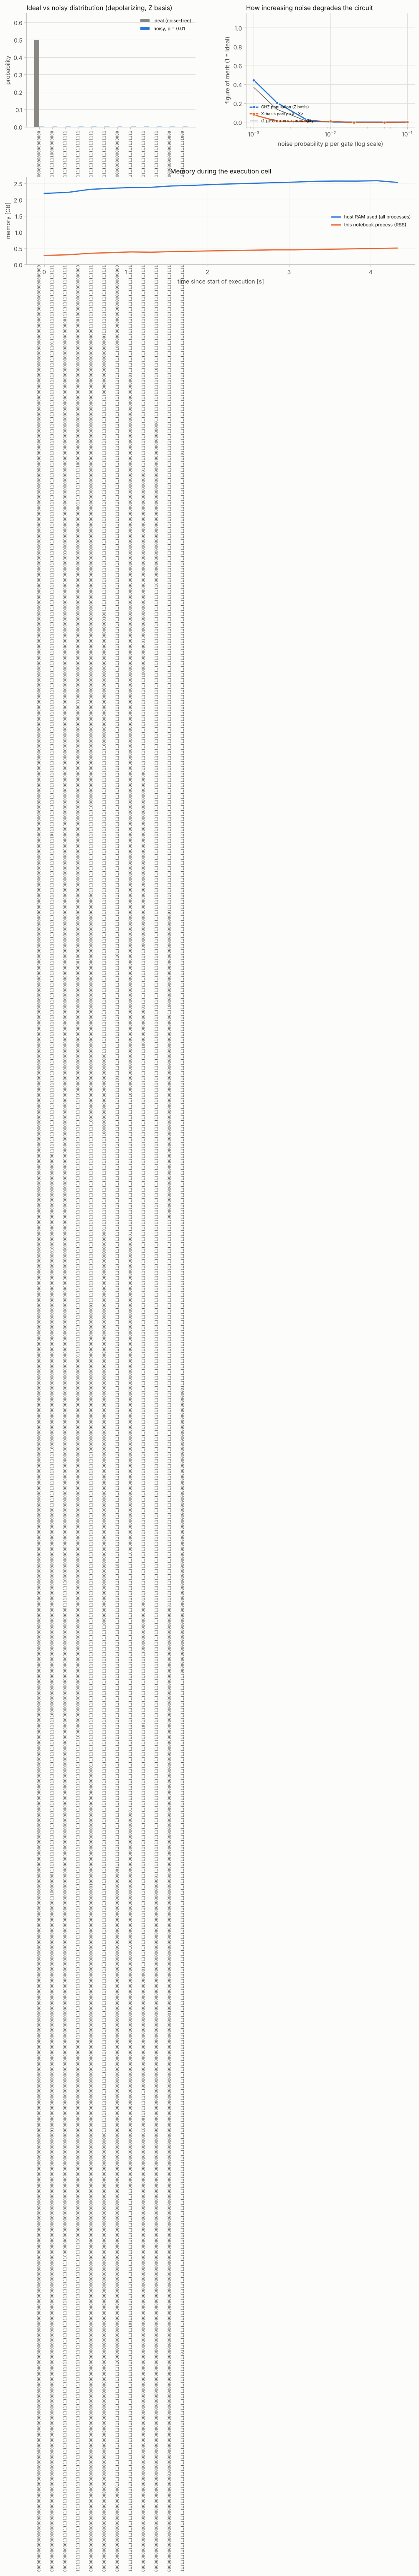

In [10]:
# ---------------------------------------------------------------------------------
# Section 9 - Ideal vs noisy distributions, counts and the noise sweep
# ---------------------------------------------------------------------------------
if not execution_ok:
    print("Skipped: the execution cell failed (see the error message above).")
else:
    noisy_counts = results[p_main]["Z"][0]
    ideal_counts = results[0.0]["Z"][0] if 0.0 in results else {}
    top = sorted(noisy_counts.items(), key=lambda kv: kv[1], reverse=True)[:12]
    print(f"Most frequent outcomes at p = {p_main} (Z basis, {SHOTS} shots):")
    print(f"  {'bitstring':<{max(9, N_QUBITS)}}  {'noisy counts':>12}  {'noiseless counts':>16}  {'ideal P':>8}")
    for b, c in top:
        print(f"  {b:<{max(9, N_QUBITS)}}  {c:>12}  {ideal_counts.get(b, 0):>16}  {ideal.get(b, 0.0):>8.3f}")
    print(f"\n{'p':>8} {'Hellinger F':>12} {'population':>11} {'X parity':>9} {'state F':>8} {'(1-p)^G':>8} {'outcomes':>9}")
    for p in sweep:
        m = metrics[p]
        print(f"{p:>8g} {m['hellinger']:>12.4f} {m['population']:>11.4f} {m.get('parity_x', float('nan')):>9.4f} "
              f"{m.get('state_fidelity', float('nan')):>8.4f} {m['lower_bound']:>8.4f} {m['distinct']:>9}")

    fig = plt.figure(figsize=(12, 7.8))
    grid = fig.add_gridspec(2, 2, height_ratios=[1.1, 0.85], hspace=0.5, wspace=0.3)
    ax_d = fig.add_subplot(grid[0, 0])
    labels = [b for b, _ in top]
    xpos = np.arange(len(labels))
    ax_d.bar(xpos - 0.2, [ideal.get(b, 0.0) for b in labels], width=0.38, color=INK_MUTED, label="ideal (noise-free)")
    ax_d.bar(xpos + 0.2, [c / SHOTS for _, c in top], width=0.38, color=BLUE, label=f"noisy, p = {p_main}")
    ax_d.set_xticks(xpos, labels, rotation=90, fontsize=7, family="DejaVu Sans Mono")
    ax_d.set_ylabel("probability")
    ax_d.set_ylim(0, max(ideal.values()) * 1.3)
    ax_d.set_title(f"Ideal vs noisy distribution ({noise_kind}, Z basis)", loc="left")
    ax_d.legend(fontsize=8, loc="upper right")
    ax_d.grid(axis="x", visible=False)

    ax_s = fig.add_subplot(grid[0, 1])
    ps = np.array([p for p in sweep if p > 0])
    # For these circuits the Hellinger fidelity equals the population (GHZ: when both peaks are balanced),
    # so the plot shows the population and adds the X-basis parity / exact state fidelity where available.
    series = [("population", "GHZ population (Z basis)" if circuit == "ghz" else "P(0...0) = Hellinger fidelity", BLUE)]
    if circuit == "ghz" and MEASURE_X_BASIS:
        series.append(("parity_x", "X-basis parity <X...X>", ORANGE))
    if "state_fidelity" in metrics[p_main]:
        series.append(("state_fidelity", "exact state fidelity (density matrix)", AQUA))
    for key, label, color in series:
        ax_s.plot(ps, [metrics[p][key] for p in ps], "-o", color=color, markersize=5, markeredgecolor=SURFACE, label=label)
    ax_s.plot(ps, [metrics[p]["lower_bound"] for p in ps], color=INK_SECONDARY, linewidth=1.0,
              label="(1-p)^G no-error probability")
    ax_s.set_xscale("log")
    ax_s.set_ylim(-0.05, 1.15)
    ax_s.set_xlabel("noise probability p per gate (log scale)")
    ax_s.set_ylabel("figure of merit (1 = ideal)")
    ax_s.set_title("How increasing noise degrades the circuit", loc="left")
    ax_s.legend(fontsize=7, loc="lower left")

    ax_m = fig.add_subplot(grid[1, :])
    monitor.plot(ax=ax_m, title="Memory during the execution cell")
    plt.show()

---
## Section 10 - Final benchmark report

                                       FINAL BENCHMARK REPORT                                       
Algorithm                         : Quantum noise simulation
Date (UTC)                        : 2026-11-07 17:08:39
CUDA-Q version                    : 0.16.0
Number of qubits                  : 1000
Backend (requested -> used)       : cpu -> cpu
CUDA-Q target                     : stim
Simulation method                 : stabilizer
Numerical precision               : fp64
Number of shots                   : 10000
Circuit construction time         : 0.0153 s
Compilation time (MLIR + JIT)     : 0.0618 s
Quantum execution time            : 4.0534 s
Total wall time of execution cell : 4.2593 s
Timing method                     : CUDA-Q span tracer (first launch)
Peak host RAM used                : 2.58 GB (15.3% of 16.9 GB)
Peak notebook process RSS         : 0.50 GB (baseline 0.28 GB)
Peak GPU memory                   : not available - nvidia-ml-py (pynvml) is not installed
Node / MPI ra

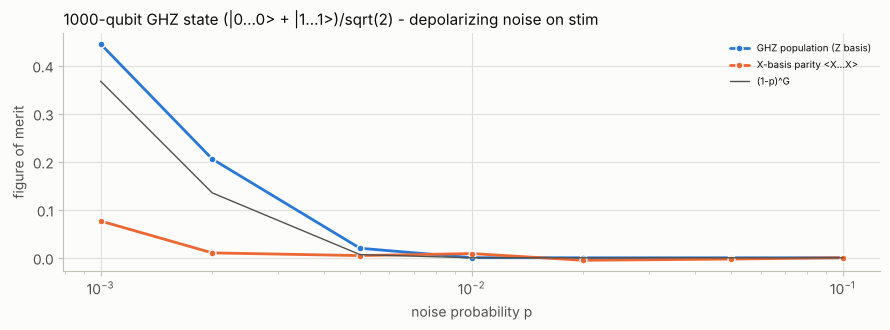

In [11]:
# ---------------------------------------------------------------------------------
# Section 10 - Final benchmark report
# ---------------------------------------------------------------------------------
if not execution_ok:
    print(f"No report: execution failed with {type(execution_error).__name__}: {execution_error}")
else:
    phases_report = dict(phases)
    phases_report["execution_s"] = (phases["execution_s"] or 0.0) + later_time
    report = build_report("Quantum noise simulation", backend_cfg, N_QUBITS, SHOTS, phases_report, memory)
    report["Circuit"] = description
    report["Noise model"] = f"{noise_kind}, p = {p_main} after every gate ({gates_1q} 1-qubit + {gates_2q} 2-qubit gate locations)"
    report["Simulation runs"] = f"{sum(len(v) for v in results.values())} ({len(sweep)} noise values)"
    if chosen_method == "density_matrix":
        report["Shot counts"] = "drawn with NumPy from the exact diagonal of rho (see Section 8)"
    report["Expected result"] = (f"ideal: {', '.join(f'P({b})={v}' for b, v in ideal.items())}; "
                                 f"fidelity >= (1-p)^G = {main['lower_bound']:.4f}" + ("" if pauli_noise else " (bound not valid for non-Pauli noise)"))
    report["Actual result"] = (f"Hellinger F = {main['hellinger']:.4f}, population = {main['population']:.4f}"
                               + (f", X parity = {main['parity_x']:.4f}" if "parity_x" in main else "")
                               + (f", state fidelity = {main['state_fidelity']:.4f}" if "state_fidelity" in main else ""))
    report["Noiseless check (p = 0)"] = f"Hellinger F = {metrics[0.0]['hellinger']:.4f}" if 0.0 in metrics else "not run"
    final_fig, ax = plt.subplots(figsize=(9, 3.4))
    for key, label, color in series:
        ax.plot(ps, [metrics[p][key] for p in ps], "-o", color=color, markersize=5, markeredgecolor=SURFACE, label=label)
    ax.plot(ps, [metrics[p]["lower_bound"] for p in ps], color=INK_SECONDARY, linewidth=1.0, label="(1-p)^G")
    ax.set_xscale("log")
    ax.set_xlabel("noise probability p")
    ax.set_ylabel("figure of merit")
    ax.set_title(f"{description} - {noise_kind} noise on {cudaq.get_target().name}", loc="left")
    ax.legend(fontsize=7)
    final_fig.tight_layout()
    show_report(report, save=SAVE_REPORT, out_dir=EXPORT_DIR, name="noise_benchmark_report", figure=final_fig)
    plt.show()

---
### Things to try next
* `NOISE_MODEL = "phase_flip"`: the Z-basis population stays at 1 while the X-basis parity collapses - phase errors
  are only visible in a different measurement basis.
* `N_QUBITS = 50` or `100` (stabilizer method): the GHZ fidelity at fixed $p$ drops much faster for wider circuits.
* `SIMULATION_METHOD = "density_matrix"`, `N_QUBITS = 10`: compare the exact state fidelity with the measured
  Hellinger fidelity and the $(1-p)^G$ bound.
* On a GPU (`BACKEND = "gpu"`) the trajectory simulator handles non-Clifford circuits with 20-30 qubits.